
# 1. Import Libraries

We begin by importing the libraries required for data loading, exploratory data analysis, text preprocessing, Transformer-based model development, training, and evaluation.

We will use PyTorch for device management, Hugging Face Transformers for the T5 model and fine-tuning, and the Evaluate library to measure summarization performance.

In [1]:
# Data handling
import os
import re
import random
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Deep learning
import torch

# Hugging Face datasets and Transformer model
from datasets import Dataset
from transformers import (
    T5Tokenizer,
    T5ForConditionalGeneration,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
    set_seed
)

# Model evaluation
import evaluate


# 2. Load Dataset

We will load the SAMSum dataset from the CSV files provided in our project directory.

The dataset contains dialogues and their corresponding human-written summaries.

We will use three separate splits:
- Training set: Used to fine-tune the T5 model.
- Validation set: Used to monitor model performance and select the best checkpoint.
- Test set: Reserved for the final evaluation of our model.

We will initially inspect the dataset dimensions, column names, and a few sample records to understand its structure.


In [2]:
# Load the datasets
train_df = pd.read_csv("samsum-train.csv")
validation_df = pd.read_csv("samsum-validation.csv")
test_df = pd.read_csv("samsum-test.csv")

# Check dataset dimensions
print("Training set shape:", train_df.shape)
print("Validation set shape:", validation_df.shape)
print("Test set shape:", test_df.shape)

# Check column names
print("\nColumns:", train_df.columns.tolist())

# Display sample records
display(train_df.head(3))


Training set shape: (14732, 3)
Validation set shape: (818, 3)
Test set shape: (819, 3)

Columns: ['id', 'dialogue', 'summary']


,id,dialogue,summary
0,13818513,Amanda: I baked cookies. Do you want some?\r\...,Amanda baked cookies and will bring Jerry some...
1,13728867,Olivia: Who are you voting for in this electio...,Olivia and Olivier are voting for liberals in ...
2,13681000,"Tim: Hi, what's up?\r\nKim: Bad mood tbh, I wa...",Kim may try the pomodoro technique recommended...


# 3. Data Understanding

In this section, we will inspect the structure, data types, missing values, and duplicate records in our datasets before proceeding to EDA.

In [3]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14732 entries, 0 to 14731
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   id        14732 non-null  str  
 1   dialogue  14731 non-null  str  
 2   summary   14732 non-null  str  
dtypes: str(3)
memory usage: 9.2 MB


In [4]:

train_df.describe(include="all")


,id,dialogue,summary
count,14732,14731,14732
unique,14732,14264,14730
top,13818513,"Jimmy: Hey, guess what? My car's completely ka...",Frank likes Macy's red outfit.
freq,1,4,2


In [5]:

print(train_df.isnull().sum())
print("\nValidation:\n", validation_df.isnull().sum())
print("\nTest:\n", test_df.isnull().sum())


id          0
dialogue    1
summary     0
dtype: int64

Validation:
 id          0
dialogue    0
summary     0
dtype: int64

Test:
 id          0
dialogue    0
summary     0
dtype: int64


In [6]:

print("Training duplicates:", train_df.duplicated().sum())
print("Validation duplicates:", validation_df.duplicated().sum())
print("Test duplicates:", test_df.duplicated().sum())


Training duplicates: 0
Validation duplicates: 0
Test duplicates: 0


In [7]:

print("Training duplicate IDs:", train_df["id"].duplicated().sum())
print("Validation duplicate IDs:", validation_df["id"].duplicated().sum())
print("Test duplicate IDs:", test_df["id"].duplicated().sum())


Training duplicate IDs: 0
Validation duplicate IDs: 0
Test duplicate IDs: 0


In [8]:

print("Training columns:", train_df.columns.tolist())
print("Validation columns:", validation_df.columns.tolist())
print("Test columns:", test_df.columns.tolist())


Training columns: ['id', 'dialogue', 'summary']
Validation columns: ['id', 'dialogue', 'summary']
Test columns: ['id', 'dialogue', 'summary']



# 4. Exploratory Data Analysis (EDA)

In this section, we will explore the dialogue and summary lengths in the SAMSum dataset and examine a few examples.

This will help us understand the nature of the text and choose suitable tokenization and sequence-length settings for our T5 model.


In [9]:

train_df[["dialogue", "summary"]].head(3)


,dialogue,summary
0,Amanda: I baked cookies. Do you want some?\r\...,Amanda baked cookies and will bring Jerry some...
1,Olivia: Who are you voting for in this electio...,Olivia and Olivier are voting for liberals in ...
2,"Tim: Hi, what's up?\r\nKim: Bad mood tbh, I wa...",Kim may try the pomodoro technique recommended...


In [10]:
### Dialogue and Summary Length Analysis
train_df["dialogue_words"] = train_df["dialogue"].apply(lambda x: len(str(x).split()))
train_df["summary_words"] = train_df["summary"].apply(lambda x: len(str(x).split()))

train_df[["dialogue_words", "summary_words"]].describe()


,dialogue_words,summary_words
count,14732.000000,14732.000000
mean,93.786451,20.317472
std,74.033371,11.153815
min,1.000000,1.000000
25%,39.000000,12.000000
50%,73.000000,18.000000
75%,128.000000,27.000000
max,803.000000,64.000000


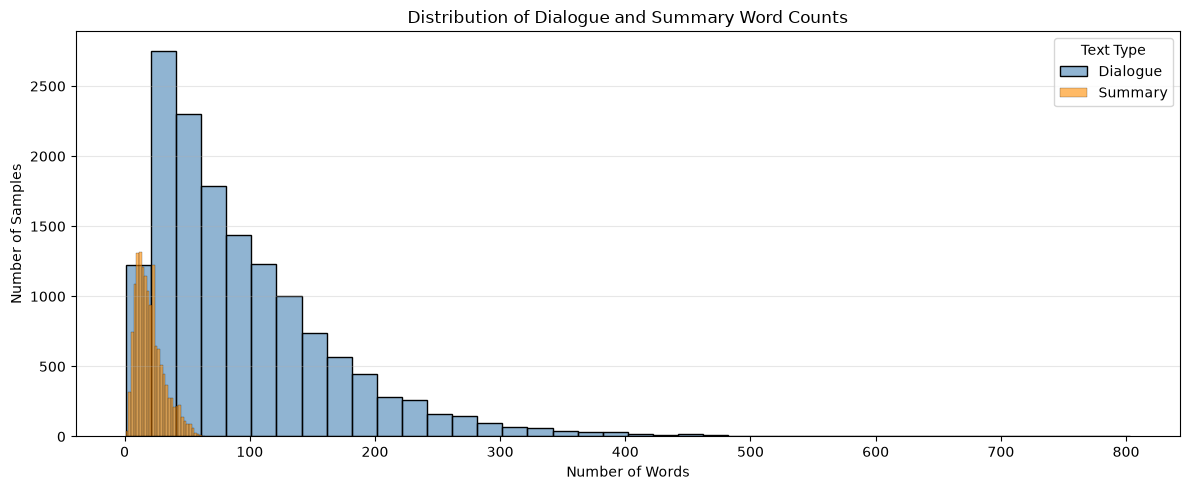

In [11]:

plt.figure(figsize=(12, 5))

sns.histplot(
    data=train_df,
    x="dialogue_words",
    bins=40,
    color="steelblue",
    label="Dialogue",
    alpha=0.6
)

sns.histplot(
    data=train_df,
    x="summary_words",
    bins=30,
    color="darkorange",
    label="Summary",
    alpha=0.6
)

plt.title("Distribution of Dialogue and Summary Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of Samples")
plt.legend(title="Text Type")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



# 5. Data Preparation and Tokenization

In this section, we will prepare the text data, clean unnecessary characters and whitespace, and tokenize the dialogues and their corresponding summaries for training our T5 model.


In [12]:

# Select a smaller dataset for initial training
train_df = train_df.sample(n=4000, random_state=42).reset_index(drop=True)
validation_df = validation_df.sample(n=500, random_state=42).reset_index(drop=True)

print("Training samples:", len(train_df))
print("Validation samples:", len(validation_df))
print("Test samples:", len(test_df))


Training samples: 4000
Validation samples: 500
Test samples: 819


In [13]:

# Clean the text

def clean_data(text):
    if pd.isna(text):
        return ""

    text = re.sub(r"<[^>]+>", " ", text)  # Remove HTML tags
    text = re.sub(r"\s+", " ", text)      # Normalize whitespace

    return text.strip()


# Apply cleaning to all datasets
train_df["dialogue"] = train_df["dialogue"].apply(clean_data)
train_df["summary"] = train_df["summary"].apply(clean_data)

validation_df["dialogue"] = validation_df["dialogue"].apply(clean_data)
validation_df["summary"] = validation_df["summary"].apply(clean_data)

test_df["dialogue"] = test_df["dialogue"].apply(clean_data)
test_df["summary"] = test_df["summary"].apply(clean_data)


In [14]:
print("Training empty dialogues:", (train_df["dialogue"] == "").sum())
print("Training empty summaries:", (train_df["summary"] == "").sum())

print("Validation empty dialogues:", (validation_df["dialogue"] == "").sum())
print("Validation empty summaries:", (validation_df["summary"] == "").sum())

print("Test empty dialogues:", (test_df["dialogue"] == "").sum())
print("Test empty summaries:", (test_df["summary"] == "").sum())

Training empty dialogues: 0
Training empty summaries: 0
Validation empty dialogues: 0
Validation empty summaries: 0
Test empty dialogues: 0
Test empty summaries: 0


In [15]:

MODEL_NAME = "t5-small"

tokenizer = T5Tokenizer.from_pretrained(MODEL_NAME)


In [16]:

train_dataset = Dataset.from_pandas(
    train_df[["dialogue", "summary"]],
    preserve_index=False
)

validation_dataset = Dataset.from_pandas(
    validation_df[["dialogue", "summary"]],
    preserve_index=False
)

test_dataset = Dataset.from_pandas(
    test_df[["dialogue", "summary"]],
    preserve_index=False
)


In [17]:

def tokenize_data(examples):
    # Prepare dialogue inputs for T5
    inputs = ["summarize: " + dialogue for dialogue in examples["dialogue"]]

    model_inputs = tokenizer(
        inputs,
        max_length=512,
        truncation=True
    )

    # Tokenize the reference summaries
    labels = tokenizer(
        text_target=examples["summary"],
        max_length=150,
        truncation=True
    )

    model_inputs["labels"] = labels["input_ids"]

    return model_inputs


In [18]:

train_dataset = train_dataset.map(
    tokenize_data,
    batched=True,
    remove_columns=["dialogue", "summary"]
)

validation_dataset = validation_dataset.map(
    tokenize_data,
    batched=True,
    remove_columns=["dialogue", "summary"]
)

test_dataset = test_dataset.map(
    tokenize_data,
    batched=True,
    remove_columns=["dialogue", "summary"]
)


Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/819 [00:00<?, ? examples/s]

In [19]:

print("Dataset columns:", train_dataset.column_names)

print("\nTokenized dialogue:")
print(tokenizer.decode(
    train_dataset[0]["input_ids"],
    skip_special_tokens=True
))

print("\nTokenized summary:")
print(tokenizer.decode(
    train_dataset[0]["labels"],
    skip_special_tokens=True
))


Dataset columns: ['input_ids', 'attention_mask', 'labels']

Tokenized dialogue:
summarize: Violet: hi! i came across this Austin's article and i thought that you might find it interesting Violet: Claire: Hi! :) Thanks, but I've already read it. :) Claire: But thanks for thinking about me :)

Tokenized summary:
Violet sent Claire Austin's article.


In [20]:
# Calculate token lengths without truncating the text
dialogue_lengths = train_df["dialogue"].apply(
    lambda text: len(
        tokenizer("summarize: " + text, truncation=False)["input_ids"]
    )
)

summary_lengths = train_df["summary"].apply(
    lambda text: len(
        tokenizer(text_target=text, truncation=False)["input_ids"]
    )
)

print("Dialogue token lengths:")
print(dialogue_lengths.describe(percentiles=[0.90, 0.95, 0.99]))

print("\nSummary token lengths:")
print(summary_lengths.describe(percentiles=[0.90, 0.95, 0.99]))

print("\nDialogues exceeding 512 tokens:", (dialogue_lengths > 512).sum())
print("Summaries exceeding 150 tokens:", (summary_lengths > 150).sum())

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (594 > 512). Running this sequence through the model will result in indexing errors


Dialogue token lengths:
count    4000.000000
mean      150.067500
std       110.710725
min        16.000000
90%       299.000000
95%       367.000000
99%       518.030000
max      1149.000000
Name: dialogue, dtype: float64

Summary token lengths:
count    4000.000000
mean       28.534250
std        14.902545
min         5.000000
90%        49.000000
95%        58.000000
99%        73.000000
max        94.000000
Name: summary, dtype: float64

Dialogues exceeding 512 tokens: 43
Summaries exceeding 150 tokens: 0


## 6. Pretrained Model Baseline

In this section, we load the pretrained T5-small model and examine its summarization output before fine-tuning it on the SAMSum dataset.

This baseline helps us understand the model's initial performance and gives us a reference point for comparison after training.

In [21]:
# Select the device for model execution
# Select the device for model execution
if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Using device:", device)

Using device: cuda


In [22]:
# Load the pretrained T5 model
model = T5ForConditionalGeneration.from_pretrained(MODEL_NAME)

# Move the model to the selected device
model = model.to(device)

# Set the model to evaluation mode
model.eval()

print("Pretrained model loaded successfully.")

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Pretrained model loaded successfully.


In [23]:
# Select one example from the validation dataset
sample_dialogue = validation_df.iloc[0]["dialogue"]
reference_summary = validation_df.iloc[0]["summary"]

print("Original dialogue:\n")
print(sample_dialogue)

print("\nReference summary:\n")
print(reference_summary)

Original dialogue:

Edd: wow, did you hear that they're transferring us to a different department? Rose: whaaaaat :o Rose: no! where'd you hear that? Edd: well, it's quite official Edd: Anderson just told us Rose: and do you know what it changes for us? Edd: they won't change the professors Edd: but i know the paperwork will get trickier Rose: and i guess that is a move that is supposed to make everything easier Edd: yeah, guess so Edd: they have a funny way of understanding 'to make things easier'

Reference summary:

Rose and Edd will be transferred to a new department. Their professors will not change but paperwork will become more difficult.


In [24]:
# Add the task prefix expected by our summarization input
input_text = "summarize: " + sample_dialogue

# Convert the dialogue into tensors for PyTorch
input_tokens = tokenizer(
    input_text,
    max_length=512,
    truncation=True,
    return_tensors="pt"
)

# Move the tokenized input to the same device as the model
input_tokens = input_tokens.to(device)

# Generate a summary without calculating gradients
with torch.no_grad():
    output_ids = model.generate(
        input_ids=input_tokens["input_ids"],
        attention_mask=input_tokens["attention_mask"],
        max_new_tokens=100,
        num_beams=4
    )

# Convert the generated token IDs back into readable text
predicted_summary = tokenizer.decode(
    output_ids[0],
    skip_special_tokens=True
)

print("Pretrained model summary:\n")
print(predicted_summary)

Pretrained model summary:

rose: 'they have a funny way of understanding 'to make things easier' Edd: 'they have a funny way of understanding 'to make things easier'


## 7. Fine-tuning T5-small

In this section, we will fine-tune the pretrained T5-small model on our prepared SAMSum dataset. The model will learn from dialogue-summary pairs to improve its ability to generate concise summaries.

We will use Hugging Face's `Seq2SeqTrainer` to manage the training process, evaluate the model on validation data, and save checkpoints.

In [25]:
# Prepare batches for sequence-to-sequence training
data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model
)

In [26]:
# Set a seed for reproducibility
set_seed(42)

# Configure fine-tuning
training_args = Seq2SeqTrainingArguments(
    output_dir="./briefwise_checkpoints",
    num_train_epochs=3,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    learning_rate=0.00005,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False
)

In [27]:
trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=validation_dataset,
    processing_class=tokenizer,
    data_collator=data_collator
)

In [28]:
training_results = trainer.train()

Epoch,Training Loss,Validation Loss
1,2.098069,1.852062
2,1.960152,1.812382
3,1.920695,1.805675


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight', 'lm_head.weight'].


## 8. ROUGE Evaluation Setup

ROUGE is a common evaluation metric for text summarization. It compares the summaries generated by our model with the human-written reference summaries.

We will use ROUGE scores to compare different hyperparameter configurations and identify which produces better summaries on the validation dataset.

In [29]:
# Load the ROUGE evaluation metric
rouge = evaluate.load("rouge")

In [30]:
def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    # Handle an alternative prediction format
    if isinstance(predictions, tuple):
        predictions = predictions[0]

    # Replace invalid negative token IDs with padding
    predictions = np.where(
        predictions < 0, tokenizer.pad_token_id, predictions
    )
    labels = np.where(
        labels < 0, tokenizer.pad_token_id, labels
    )

    # Convert token IDs back into text
    predicted_summaries = tokenizer.batch_decode(
        predictions, skip_special_tokens=True
    )
    reference_summaries = tokenizer.batch_decode(
        labels, skip_special_tokens=True
    )

    # Compare the generated summaries with the reference summaries
    scores = rouge.compute(
        predictions=predicted_summaries,
        references=reference_summaries,
        use_stemmer=True
    )

    return {
        name: round(score * 100, 2)
        for name, score in scores.items()
    }

## 9. Hyperparameter Tuning

In [31]:
def model_init(trial=None):
    return T5ForConditionalGeneration.from_pretrained(MODEL_NAME)

In [32]:
training_args = Seq2SeqTrainingArguments(
    output_dir="./briefwise_optuna",
    num_train_epochs=3,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    learning_rate=0.00005,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_rougeL",
    greater_is_better=True,
    predict_with_generate=True,
    generation_max_length=100,
    generation_num_beams=4,
    save_total_limit=1,
    report_to="none"
)

In [33]:
def optuna_hp_space(trial):
    return {
        "learning_rate": trial.suggest_float(
            "learning_rate",
            0.00001,
            0.001,
            log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay",
            0.0,
            0.1
        ),
        "per_device_train_batch_size": trial.suggest_categorical(
            "per_device_train_batch_size",
            [2, 4, 8]
        ),
        "num_train_epochs": trial.suggest_int(
            "num_train_epochs",
            2,
            5
        )
    }

In [34]:
def compute_objective(metrics):
    return metrics["eval_rougeL"]

In [35]:
data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer
)

trainer = Seq2SeqTrainer(
    model_init=model_init,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=validation_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

In [36]:
best_run = trainer.hyperparameter_search(
    backend="optuna",
    hp_space=optuna_hp_space,
    compute_objective=compute_objective,
    n_trials=10,
    direction="maximize"
)

print("Best ROUGE-L objective:", best_run.objective)
print("Best hyperparameters:", best_run.hyperparameters)

[I 2026-10-23 11:53:08,932] A new study created in memory with name: no-name-4abb5fb8-f577-4a6a-a4a4-663c7ed0347c


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum
1,2.040293,1.847670,44.550000,21.990000,37.350000,37.420000
2,1.606941,1.789193,47.490000,23.190000,38.930000,38.960000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight', 'lm_head.weight'].
[I 2026-10-23 13:21:48,197] Trial 8 finished with value: 39.24 and parameters: {'learning_rate': 0.0004919270360612876, 'weight_decay': 0.013659877433218915, 'per_device_train_batch_size': 4, 'num_train_epochs': 3}. Best is trial 8 with value: 39.24.


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum
1,2.147059,1.913970,40.820000,18.020000,33.850000,33.870000


[I 2026-10-23 13:24:57,444] Trial 9 pruned. 


Best ROUGE-L objective: 39.24
Best hyperparameters: {'learning_rate': 0.0004919270360612876, 'weight_decay': 0.013659877433218915, 'per_device_train_batch_size': 4, 'num_train_epochs': 3}


## 10. Final Model Training

In [37]:
best_hyperparameters = best_run.hyperparameters

print("Best validation ROUGE-L:", best_run.objective)
print("\nBest hyperparameters:")

for parameter, value in best_hyperparameters.items():
    print(f"{parameter}: {value}")

Best validation ROUGE-L: 39.24

Best hyperparameters:
learning_rate: 0.0004919270360612876
weight_decay: 0.013659877433218915
per_device_train_batch_size: 4
num_train_epochs: 3


In [38]:
final_training_args = Seq2SeqTrainingArguments(
    output_dir="./briefwise_final",

    # Use the best hyperparameters found by Optuna
    num_train_epochs=best_hyperparameters["num_train_epochs"],
    per_device_train_batch_size=best_hyperparameters[
        "per_device_train_batch_size"
    ],
    learning_rate=best_hyperparameters["learning_rate"],
    weight_decay=best_hyperparameters["weight_decay"],

    # Keep evaluation batch size fixed
    per_device_eval_batch_size=4,

    # Evaluate and save after each epoch
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",

    # Select the checkpoint with the best validation ROUGE-L
    load_best_model_at_end=True,
    metric_for_best_model="eval_rougeL",
    greater_is_better=True,

    # Settings for generating summaries during evaluation
    predict_with_generate=True,
    generation_max_length=100,
    generation_num_beams=4,

    save_total_limit=2,
    report_to="none"
)

print("Final training configuration created.")

Final training configuration created.


In [39]:
final_trainer = Seq2SeqTrainer(
    model_init=model_init,
    args=final_training_args,
    train_dataset=train_dataset,
    eval_dataset=validation_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

In [40]:
final_train_result = final_trainer.train()

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum
1,2.084382,1.822407,45.580000,22.030000,37.930000,38.020000
2,1.704431,1.770085,47.420000,23.250000,39.030000,39.110000
3,1.482916,1.777349,48.080000,23.990000,39.760000,39.790000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight', 'lm_head.weight'].


In [41]:
final_trainer.save_model("./briefwise_final")
tokenizer.save_pretrained("./briefwise_final")

print("Final model and tokenizer saved successfully.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Final model and tokenizer saved successfully.


## 11. Baseline vs Fine-Tuned Model Comparison

In [42]:
# Load the original pretrained model
baseline_model = T5ForConditionalGeneration.from_pretrained(
    MODEL_NAME
).to(device)

# Load our fine-tuned BriefWise model
finetuned_model = T5ForConditionalGeneration.from_pretrained(
    "./briefwise_final"
).to(device)

# Set both models to evaluation mode
baseline_model.eval()
finetuned_model.eval()

print("Both models loaded successfully.")

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Both models loaded successfully.


In [43]:
def generate_summaries(model, dialogues, batch_size=4):
    generated_summaries = []

    for start in range(0, len(dialogues), batch_size):
        batch_dialogues = dialogues[start:start + batch_size]

        # Add T5's summarization instruction
        inputs = [
            "summarize: " + dialogue
            for dialogue in batch_dialogues
        ]

        # Convert dialogues into model inputs
        input_tokens = tokenizer(
            inputs,
            max_length=512,
            truncation=True,
            padding=True,
            return_tensors="pt"
        ).to(device)

        # Generate summaries without calculating gradients
        with torch.no_grad():
            output_ids = model.generate(
                input_ids=input_tokens["input_ids"],
                attention_mask=input_tokens["attention_mask"],
                max_new_tokens=100,
                num_beams=4
            )

        # Convert generated token IDs into readable text
        batch_summaries = tokenizer.batch_decode(
            output_ids,
            skip_special_tokens=True
        )

        generated_summaries.extend(batch_summaries)

    return generated_summaries

In [44]:
test_dialogues = test_df["dialogue"].tolist()
reference_summaries = test_df["summary"].tolist()

baseline_predictions = generate_summaries(
    baseline_model,
    test_dialogues
)

finetuned_predictions = generate_summaries(
    finetuned_model,
    test_dialogues
)

print("Number of test dialogues:", len(test_dialogues))
print("Baseline summaries generated:", len(baseline_predictions))
print("Fine-tuned summaries generated:", len(finetuned_predictions))

[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

Number of test dialogues: 819
Baseline summaries generated: 819
Fine-tuned summaries generated: 819


In [45]:
# Evaluate the original pretrained model
baseline_scores = rouge.compute(
    predictions=baseline_predictions,
    references=reference_summaries,
    use_stemmer=True
)

# Evaluate the fine-tuned BriefWise model
finetuned_scores = rouge.compute(
    predictions=finetuned_predictions,
    references=reference_summaries,
    use_stemmer=True
)

# Display the scores as percentages
comparison_results = pd.DataFrame({
    "Metric": ["ROUGE-1", "ROUGE-2", "ROUGE-L"],
    "Pretrained T5-small": [
        round(baseline_scores["rouge1"] * 100, 2),
        round(baseline_scores["rouge2"] * 100, 2),
        round(baseline_scores["rougeL"] * 100, 2)
    ],
    "Fine-tuned BriefWise": [
        round(finetuned_scores["rouge1"] * 100, 2),
        round(finetuned_scores["rouge2"] * 100, 2),
        round(finetuned_scores["rougeL"] * 100, 2)
    ]
})

display(comparison_results)

,Metric,Pretrained T5-small,Fine-tuned BriefWise
0,ROUGE-1,27.40,46.95
1,ROUGE-2,7.64,22.55
2,ROUGE-L,21.21,38.54


In [46]:
comparison_examples = pd.DataFrame({
    "Dialogue": test_dialogues[:5],
    "Reference Summary": reference_summaries[:5],
    "Pretrained Summary": baseline_predictions[:5],
    "Fine-tuned Summary": finetuned_predictions[:5]
})

display(comparison_examples)

,Dialogue,Reference Summary,Pretrained Summary,Fine-tuned Summary
0,"Hannah: Hey, do you have Betty's number? Amand...",Hannah needs Betty's number but Amanda doesn't...,"Amanda: Lemme check Hannah: Sorry, can't find ...",Amanda can't find Betty's number. Larry called...
1,Eric: MACHINE! Rob: That's so gr8! Eric: I kno...,Eric and Rob are going to watch a stand-up on ...,Rob: I know! I especially like the train part!...,Rob likes the train part. Eric will watch some...
2,"Lenny: Babe, can you help me with something? B...",Lenny can't decide which trousers to buy. Bob ...,Bob: what matters is what you'll give you the ...,Bob wants Lenny to pick a pair of purple trous...
3,"Will: hey babe, what do you want for dinner to...",Emma will be home soon and she will let Will k...,"Emma: hey babe, what do you want for dinner to...",Emma will pick Will up her for dinner tonight.
4,"Ollie: Hi , are you in Warsaw Jane: yes, just ...",Jane is in Warsaw. Ollie and Jane has a party....,oh oh oh... very strange! i have to be careful...,Jane lost her calendar. Ollie and Jane will me...


In [47]:
for i in range(5):
    print(f"\n{'=' * 20} Example {i} {'=' * 20}")

    print("\nDIALOGUE:")
    print(test_dialogues[i])

    print("\nREFERENCE SUMMARY:")
    print(reference_summaries[i])

    print("\nPRETRAINED MODEL:")
    print(baseline_predictions[i])

    print("\nFINE-TUNED MODEL:")
    print(finetuned_predictions[i])


==================== Example 0 ====================

DIALOGUE:
Hannah: Hey, do you have Betty's number? Amanda: Lemme check Hannah: Amanda: Sorry, can't find it. Amanda: Ask Larry Amanda: He called her last time we were at the park together Hannah: I don't know him well Hannah: Amanda: Don't be shy, he's very nice Hannah: If you say so.. Hannah: I'd rather you texted him Amanda: Just text him 🙂 Hannah: Urgh.. Alright Hannah: Bye Amanda: Bye bye

REFERENCE SUMMARY:
Hannah needs Betty's number but Amanda doesn't have it. She needs to contact Larry.

PRETRAINED MODEL:
Amanda: Lemme check Hannah: Sorry, can't find it. Amanda: Ask Larry Amanda: He called her last time we were at the park together Hannah: I don't know him well Hannah: Amanda: Don't be shy, he's very nice Hannah: If you say so.. Alright Hannah: Bye bye: Bye bye bye bye bye bye bye bye bye bye bye bye by

FINE-TUNED MODEL:
Amanda can't find Betty's number. Larry called Betty last time they were at the park together.

========

## 12. Conclusion

In this project, we developed **BriefWise**, a text summarization system using the pretrained T5-small model and fine-tuned it on the SAMSum dialogue summarization dataset. The workflow included data exploration, text cleaning, tokenization, baseline evaluation, fine-tuning, and hyperparameter optimization using Optuna.

We compared the original pretrained model with our fine-tuned model using ROUGE metrics on the test dataset. The fine-tuned model achieved ROUGE-1, ROUGE-2, and ROUGE-L scores of **47.68, 22.64, and 38.71**, respectively, outperforming the pretrained model's scores of 27.40, 7.64, and 21.21.

Although the results demonstrate improved overlap with human-written summaries, qualitative evaluation revealed some factual errors, including incorrect speaker attribution and misunderstandings of events. This highlights the importance of evaluating both numerical metrics and the actual generated summaries.

Overall, this project demonstrates how transfer learning and hyperparameter tuning can improve dialogue summarization. The saved fine-tuned model will serve as the foundation for integrating BriefWise with a FastAPI backend and a user interface. Further improvements will focus on summary accuracy, reliable inference, and testing the complete application.